# 4. Historische Umsätze prognostizieren

Ziel: Prophet für drei Filialen verwenden und für Filiale 1 einen zeitlich getrennten Test samt einfacher Wochen-Baseline berechnen. Forecasts beginnen nach dem Datenende 2015.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Notebook im Projektordner oder in notebooks/ starten.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import pandas as pd
from prophet import Prophet
from sklearn.metrics import mean_absolute_error

from src.forecasting import load_sales, prepare_store_data, forecast_store

sales = load_sales()
data = prepare_store_data(sales, 1)
print(f"Verkaufstage: {len(sales)}; Datenstand: {sales['Date'].max():%Y-%m-%d}")
data.head()

Verkaufstage: 2344; Datenstand: 2015-07-31
Out[0]: 
             ds     y
2820 2013-01-02  5530
2817 2013-01-03  4327
2814 2013-01-04  4486
2811 2013-01-05  4997
2805 2013-01-07  7176


Prophet erwartet `ds` für das Datum und `y` für den Zielwert. Trainiert wird nur auf geöffneten Tagen mit positivem Umsatz. Die Vorhersage beschreibt daher Verkaufstage; Feiertage und Schließtage sind noch kein eigenes Modellmerkmal.

In [3]:
model, forecast = forecast_store(sales, store_id=1, days=30)
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail()

Out[0]: 
            ds         yhat   yhat_lower   yhat_upper
806 2015-08-26  4047.216626  2950.390405  5130.668791
807 2015-08-27  3956.275231  2866.438280  5102.583268
808 2015-08-28  4206.534494  3156.542102  5343.093441
809 2015-08-29  4404.623379  3405.040338  5559.546591
810 2015-08-30  4391.304006  3280.513967  5382.643352


17:34:58 - cmdstanpy - INFO - Chain [1] start processing
17:34:58 - cmdstanpy - INFO - Chain [1] done processing


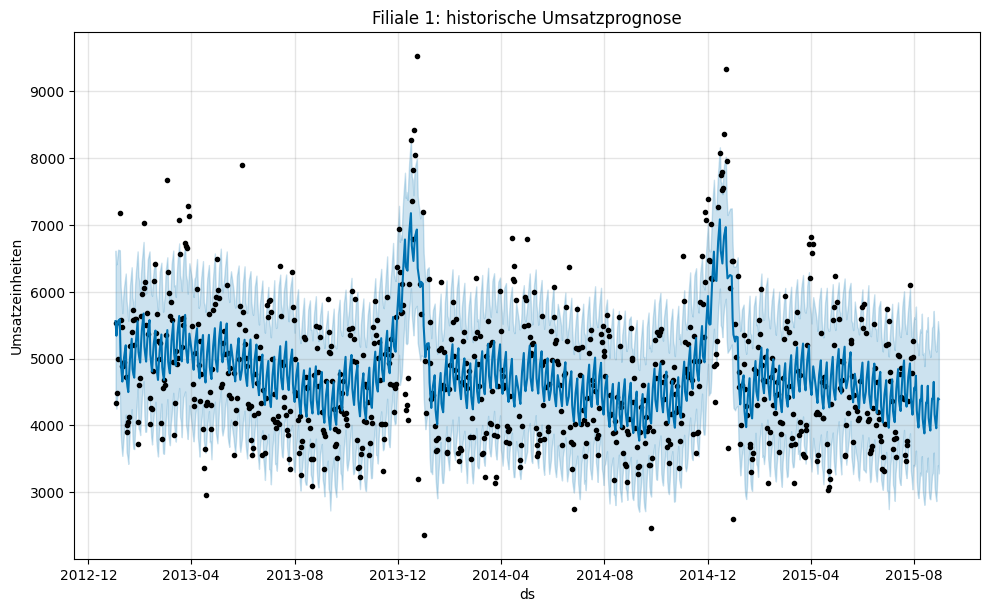

In [4]:
import matplotlib.pyplot as plt

model.plot(forecast)
plt.title("Filiale 1: historische Umsatzprognose")
plt.ylabel("Umsatzeinheiten")
plt.show()

Zeitlicher Test: Die letzten 30 Kalendertage werden zurückgehalten. Bewertet werden nur darin vorhandene Verkaufstage. Die Baseline wiederholt je Wochentag den letzten vor dem Test bekannten Umsatz. Während des Tests wird sie nicht mit Testwerten aktualisiert.

In [5]:
cutoff = data["ds"].max() - pd.Timedelta(days=30)
train = data.loc[data["ds"] <= cutoff].copy()
test = data.loc[data["ds"] > cutoff].copy()
validation_model = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
validation_model.fit(train, seed=42)
predictions = validation_model.predict(test[["ds"]])
mae = mean_absolute_error(test["y"], predictions["yhat"])
normalized_mae = mae / test["y"].mean()
last_weekday_sales = train.assign(weekday=train["ds"].dt.dayofweek).groupby("weekday")["y"].last()
baseline_predictions = test["ds"].dt.dayofweek.map(last_weekday_sales).fillna(train["y"].mean())
baseline_mae = mean_absolute_error(test["y"], baseline_predictions)
print(f"Test: {len(test)} Verkaufstage nach {cutoff:%Y-%m-%d}")
print(f"Prophet-MAE: {mae:.2f} Umsatzeinheiten")
print(f"MAE / mittlerer Ist-Umsatz: {normalized_mae:.2%} (kein MAPE)")
print(f"Wochen-Baseline-MAE: {baseline_mae:.2f} Umsatzeinheiten")

Test: 26 Verkaufstage nach 2015-07-01
Prophet-MAE: 615.69 Umsatzeinheiten
MAE / mittlerer Ist-Umsatz: 13.79% (kein MAPE)
Wochen-Baseline-MAE: 967.81 Umsatzeinheiten


In [6]:
results = []
for store_id in sorted(sales["Store"].unique()):
    _, store_forecast = forecast_store(sales, int(store_id), days=30)
    results.append(store_forecast[["Store", "ds", "yhat", "yhat_lower", "yhat_upper"]])
output = ROOT / "data/rossmann/forecasts.csv"
pd.concat(results, ignore_index=True).to_csv(output, index=False)
print(f"Exportiert: {output.relative_to(ROOT)}")

Exportiert: data/rossmann/forecasts.csv


`yhat` ist der Modellwert. `yhat_lower` und `yhat_upper` beschreiben ein modellabhängiges Unsicherheitsintervall, keine Garantie. Der Export enthält auch angepasste historische Werte. Das Dashboard berechnet seine Prognosen selbst und liest diese Exportdatei nicht ein. Weitere zeitliche Testfenster für alle Filialen stehen noch aus.